# Module 04 — Classification

**Applied exercises only** · ISLP, Chapter 4

**Printed textbook pages:** 196–199 (exercise starting pages)  


In [1]:
# Common imports: run this cell once before starting the exercises.
# All data sets come from the ISLP package installed in the project's .venv.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from ISLP import load_data, confusion_table
from ISLP.models import ModelSpec as MS, summarize
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis as LDA,
    QuadraticDiscriminantAnalysis as QDA,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(1)

---

## Exercise 13 · Applied

**Textbook: printed page 196**

This question should be answered using the Weekly data set, which
is part of the ISLP package. This data is similar in nature to the
Smarket data from this chapter’s lab, except that it contains 1, 089
weekly returns for 21 years, from the beginning of 1990 to the end of
2010.

### Exercise 13(a)

Produce some numerical and graphical summaries of the Weekly
data. Do there appear to be any patterns?

(1089, 9)


,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today
count,1089.000,1089.000,1089.000,1089.000,1089.000,1089.000,1089.000,1089.000
mean,2000.049,0.151,0.151,0.147,0.146,0.140,1.575,0.150
std,6.033,2.357,2.357,2.361,2.360,2.361,1.687,2.357
min,1990.000,-18.195,-18.195,-18.195,-18.195,-18.195,0.087,-18.195
25%,1995.000,-1.154,-1.154,-1.158,-1.158,-1.166,0.332,-1.154
50%,2000.000,0.241,0.241,0.241,0.238,0.234,1.003,0.241
75%,2005.000,1.405,1.409,1.409,1.409,1.405,2.054,1.405
max,2010.000,12.026,12.026,12.026,12.026,12.026,9.328,12.026


Direction
Up      605
Down    484
Name: count, dtype: int64


,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today
Year,1.000,-0.032,-0.033,-0.030,-0.031,-0.031,0.842,-0.032
Lag1,-0.032,1.000,-0.075,0.059,-0.071,-0.008,-0.065,-0.075
Lag2,-0.033,-0.075,1.000,-0.076,0.058,-0.072,-0.086,0.059
Lag3,-0.030,0.059,-0.076,1.000,-0.075,0.061,-0.069,-0.071
Lag4,-0.031,-0.071,0.058,-0.075,1.000,-0.076,-0.061,-0.008
Lag5,-0.031,-0.008,-0.072,0.061,-0.076,1.000,-0.059,0.011
Volume,0.842,-0.065,-0.086,-0.069,-0.061,-0.059,1.000,-0.033
Today,-0.032,-0.075,0.059,-0.071,-0.008,0.011,-0.033,1.000


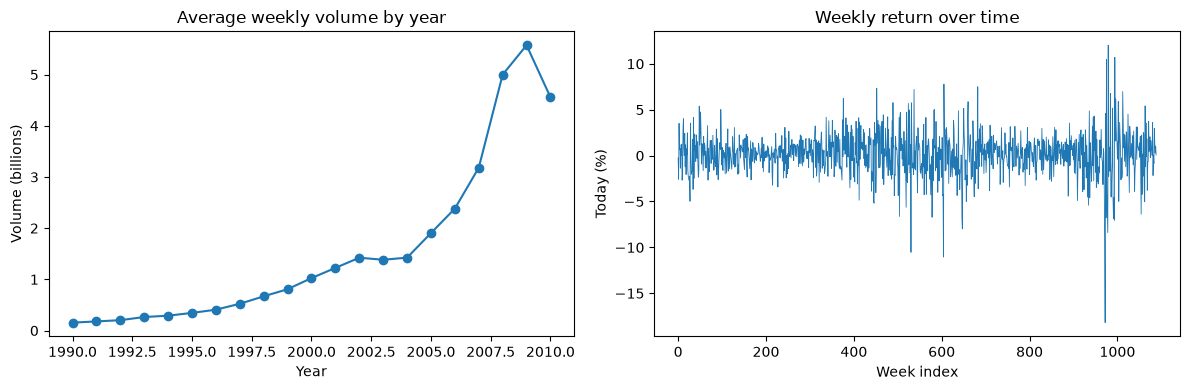

In [2]:
# Exercise 13(a)
Weekly = load_data("Weekly")
print(Weekly.shape)
display(Weekly.describe().round(3))
print(Weekly["Direction"].value_counts())
display(Weekly.drop(columns="Direction").corr().round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
Weekly.groupby("Year")["Volume"].mean().plot(ax=axes[0], marker="o")
axes[0].set(title="Average weekly volume by year", xlabel="Year", ylabel="Volume (billions)")
axes[1].plot(Weekly["Today"].values, lw=0.6)
axes[1].set(title="Weekly return over time", xlabel="Week index", ylabel="Today (%)")
plt.tight_layout()
plt.show()

### Exercise 13(b)

Use the full data set to perform a logistic regression with
Direction as the response and the five lag variables plus Volume
as predictors. Use the summary function to print the results. Do
any of the predictors appear to be statistically significant? If so,
which ones?

In [3]:
# Exercise 13(b)
lag_vars = ["Lag1", "Lag2", "Lag3", "Lag4", "Lag5", "Volume"]
X_full = MS(lag_vars).fit_transform(Weekly)
y_full = Weekly["Direction"] == "Up"
glm_full = sm.GLM(y_full, X_full, family=sm.families.Binomial()).fit()
summarize(glm_full)

,coef,std err,z,P>|z|
intercept,0.2669,0.086,3.106,0.002
Lag1,-0.0413,0.026,-1.563,0.118
Lag2,0.0584,0.027,2.175,0.030
Lag3,-0.0161,0.027,-0.602,0.547
Lag4,-0.0278,0.026,-1.050,0.294
Lag5,-0.0145,0.026,-0.549,0.583
Volume,-0.0227,0.037,-0.616,0.538


### Exercise 13(c)

Compute the confusion matrix and overall fraction of correct
predictions. Explain what the confusion matrix is telling you
about the types of mistakes made by logistic regression.

In [4]:
# Exercise 13(c)
prob_full = glm_full.predict()
labels_full = np.where(prob_full > 0.5, "Up", "Down")
display(confusion_table(labels_full, Weekly["Direction"]))
acc_full = np.mean(labels_full == Weekly["Direction"])
print(f"Training accuracy: {acc_full:.4f}")
print(f"Share of weeks that were Up: {np.mean(Weekly['Direction'] == 'Up'):.4f}")

Truth,Down,Up
Predicted,,
Down,54,48
Up,430,557


Training accuracy: 0.5611
Share of weeks that were Up: 0.5556


### Exercise 13(d)

Now fit the logistic regression model using a training data period
from 1990 to 2008, with Lag2 as the only predictor. Compute the
confusion matrix and the overall fraction of correct predictions
for the held out data (that is, the data from 2009 and 2010).

In [5]:
# Exercise 13(d)
train = Weekly["Year"] <= 2008
W_train, W_test = Weekly.loc[train], Weekly.loc[~train]
y_train, y_test = W_train["Direction"], W_test["Direction"]

X_train = MS(["Lag2"]).fit_transform(W_train)
X_test = MS(["Lag2"]).fit_transform(W_test)
glm_lag2 = sm.GLM(y_train == "Up", X_train, family=sm.families.Binomial()).fit()
print(summarize(glm_lag2))
pred_logit = np.where(glm_lag2.predict(X_test) > 0.5, "Up", "Down")
display(confusion_table(pred_logit, y_test))

test_acc = {}
test_acc["Logistic (Lag2)"] = np.mean(pred_logit == y_test)
print(f"Held-out accuracy (2009-2010): {test_acc['Logistic (Lag2)']:.4f}")

             coef  std err      z  P>|z|
intercept  0.2033    0.064  3.162  0.002
Lag2       0.0581    0.029  2.024  0.043


Truth,Down,Up
Predicted,,
Down,9,5
Up,34,56


Held-out accuracy (2009-2010): 0.6250


### Exercise 13(e)

Repeat (d) using LDA.

In [6]:
# Exercise 13(e)
lag2_train, lag2_test = W_train[["Lag2"]], W_test[["Lag2"]]
lda = LDA(store_covariance=True).fit(lag2_train, y_train)
pred_lda = lda.predict(lag2_test)
display(confusion_table(pred_lda, y_test))
test_acc["LDA (Lag2)"] = np.mean(pred_lda == y_test)
print(f"Held-out accuracy: {test_acc['LDA (Lag2)']:.4f}")

Truth,Down,Up
Predicted,,
Down,9,5
Up,34,56


Held-out accuracy: 0.6250


### Exercise 13(f)

Repeat (d) using QDA.

In [7]:
# Exercise 13(f)
qda = QDA(store_covariance=True).fit(lag2_train, y_train)
pred_qda = qda.predict(lag2_test)
display(confusion_table(pred_qda, y_test))
test_acc["QDA (Lag2)"] = np.mean(pred_qda == y_test)
print(f"Held-out accuracy: {test_acc['QDA (Lag2)']:.4f}")

Truth,Down,Up
Predicted,,
Down,0,0
Up,43,61


Held-out accuracy: 0.5865


### Exercise 13(g)

Repeat (d) using KNN with K = 1.

In [8]:
# Exercise 13(g)
knn1 = KNeighborsClassifier(n_neighbors=1).fit(lag2_train, y_train)
pred_knn1 = knn1.predict(lag2_test)
display(confusion_table(pred_knn1, y_test))
test_acc["KNN, K=1 (Lag2)"] = np.mean(pred_knn1 == y_test)
print(f"Held-out accuracy: {test_acc['KNN, K=1 (Lag2)']:.4f}")

Truth,Down,Up
Predicted,,
Down,21,30
Up,22,31


Held-out accuracy: 0.5000


### Exercise 13(h)

Repeat (d) using naive Bayes.

In [9]:
# Exercise 13(h)
nb = GaussianNB().fit(lag2_train, y_train)
pred_nb = nb.predict(lag2_test)
display(confusion_table(pred_nb, y_test))
test_acc["Naive Bayes (Lag2)"] = np.mean(pred_nb == y_test)
print(f"Held-out accuracy: {test_acc['Naive Bayes (Lag2)']:.4f}")

Truth,Down,Up
Predicted,,
Down,0,0
Up,43,61


Held-out accuracy: 0.5865


### Exercise 13(i)

Which of these methods appears to provide the best results on
this data?

In [10]:
# Exercise 13(i)
summary_13 = pd.Series(test_acc, name="held-out accuracy").sort_values(ascending=False)
display(summary_13.round(4).to_frame())
print(f"Always predicting 'Up' would give accuracy {np.mean(y_test == 'Up'):.4f}.")

,held-out accuracy
Logistic (Lag2),0.6250
LDA (Lag2),0.6250
QDA (Lag2),0.5865
Naive Bayes (Lag2),0.5865
"KNN, K=1 (Lag2)",0.5000


Always predicting 'Up' would give accuracy 0.5865.


### Exercise 13(j)

Experiment with different combinations of predictors, including possible transformations and interactions, for each of the
methods. Report the variables, method, and associated confusion matrix that appears to provide the best results on the held
out data. Note that you should also experiment with values for
K in the KNN classifier.

In [11]:
# Exercise 13(j)
# Try several predictor sets (including a transformation and an interaction) for each method.
W = Weekly.copy()
W["Lag1xLag2"] = W["Lag1"] * W["Lag2"]
W["Lag2_sq"] = W["Lag2"] ** 2
W["logVolume"] = np.log(W["Volume"])
Wtr, Wte = W.loc[train], W.loc[~train]

predictor_sets = {
    "Lag2": ["Lag2"],
    "Lag1+Lag2": ["Lag1", "Lag2"],
    "Lag2+Lag2^2": ["Lag2", "Lag2_sq"],
    "Lag1+Lag2+Lag1xLag2": ["Lag1", "Lag2", "Lag1xLag2"],
    "Lag2+logVolume": ["Lag2", "logVolume"],
    "All lags+Volume": ["Lag1", "Lag2", "Lag3", "Lag4", "Lag5", "Volume"],
}

def fit_logistic(Xtr, ytr, Xte):
    Xtr_, Xte_ = sm.add_constant(Xtr), sm.add_constant(Xte, has_constant="add")
    m = sm.GLM(ytr == "Up", Xtr_, family=sm.families.Binomial()).fit()
    return np.where(m.predict(Xte_) > 0.5, "Up", "Down")

def fit_sklearn(model):
    def f(Xtr, ytr, Xte):
        return model.fit(Xtr, ytr).predict(Xte)
    return f

methods = {
    "Logistic": fit_logistic,
    "LDA": fit_sklearn(LDA()),
    "QDA": fit_sklearn(QDA()),
    "NaiveBayes": fit_sklearn(GaussianNB()),
}
for k in [1, 5, 10, 20, 50, 100]:
    methods[f"KNN K={k}"] = fit_sklearn(KNeighborsClassifier(n_neighbors=k))

rows = []
for set_name, cols in predictor_sets.items():
    scaler = StandardScaler().fit(Wtr[cols])  # scaling matters for KNN only
    Xtr, Xte = (pd.DataFrame(scaler.transform(d[cols]), columns=cols) for d in (Wtr, Wte))
    for m_name, fit in methods.items():
        pred = fit(Xtr, Wtr["Direction"].values, Xte)
        rows.append({"predictors": set_name, "method": m_name,
                     "accuracy": np.mean(pred == Wte["Direction"].values)})
results_13j = pd.DataFrame(rows)
table_13j = results_13j.pivot(index="method", columns="predictors", values="accuracy")
display(table_13j.round(3))

best = results_13j.sort_values("accuracy", ascending=False).iloc[0]
print(f"Best combination: {best['method']} with {best['predictors']} -> accuracy {best['accuracy']:.4f}")
cols = predictor_sets[best["predictors"]]
scaler = StandardScaler().fit(Wtr[cols])
Xtr = pd.DataFrame(scaler.transform(Wtr[cols]), columns=cols)
Xte = pd.DataFrame(scaler.transform(Wte[cols]), columns=cols)
best_pred = methods[best["method"]](Xtr, Wtr["Direction"].values, Xte)
display(confusion_table(best_pred, Wte["Direction"].values))

predictors,All lags+Volume,Lag1+Lag2,Lag1+Lag2+Lag1xLag2,Lag2,Lag2+Lag2^2,Lag2+logVolume
method,,,,,,
KNN K=1,0.452,0.481,0.471,0.500,0.510,0.567
KNN K=10,0.558,0.433,0.481,0.567,0.567,0.500
KNN K=100,0.587,0.510,0.510,0.567,0.558,0.587
KNN K=20,0.558,0.548,0.529,0.596,0.596,0.510
KNN K=5,0.510,0.490,0.500,0.529,0.538,0.500
KNN K=50,0.548,0.558,0.538,0.567,0.577,0.538
LDA,0.462,0.577,0.577,0.625,0.615,0.577
Logistic,0.462,0.577,0.577,0.625,0.625,0.577
NaiveBayes,0.452,0.538,0.471,0.587,0.577,0.548


Best combination: Logistic with Lag2 -> accuracy 0.6250


Truth,Down,Up
Predicted,,
Down,9,5
Up,34,56


**Observations / conclusions**

- **(a)** The lag variables are nearly uncorrelated with each other and with `Today`. The only strong pattern is that `Volume` grows steadily over time (corr. with `Year` ≈ 0.84). 605 of the 1,089 weeks are Up.
- **(b)** Only `Lag2` is significant at the 5% level (p ≈ 0.030). `Lag1` is borderline (p ≈ 0.12).
- **(c)** Training accuracy is 56.1%, barely above the 55.6% you get by always predicting Up. The model predicts Up almost every week: it gets 557 of 605 Up weeks right but only 54 of 484 Down weeks. Most of its errors are false "Up" calls.
- **(d–h)** Trained on 1990–2008 with `Lag2` only, held-out accuracy on 2009–2010 is: logistic regression 62.5%, LDA 62.5%, QDA 58.7%, naive Bayes 58.7%, KNN (K=1) 50.0%. QDA and naive Bayes predict Up for every week, so they just match the always-Up baseline (58.7%).
- **(i)** Logistic regression and LDA (with `Lag2`) do best.
- **(j)** No transformation or interaction beat plain `Lag2`. Logistic regression and LDA with `Lag2` stay best at 62.5%, and QDA with `Lag2 + Lag2²` ties at 62.5%. Larger K helps KNN (K = 20 reaches about 60%), but it still loses to the linear methods. Weekly returns are close to unpredictable, so even 62.5% is only a few points better than the baseline.

---

## Exercise 14 · Applied

**Textbook: printed page 197**

In this problem, you will develop a model to predict whether a given
car gets high or low gas mileage based on the Auto data set.

### Exercise 14(a)

Create a binary variable, mpg01, that contains a 1 if mpg contains
a value above its median, and a 0 if mpg contains a value below
its median. You can compute the median using the median()
method of the data frame. Note you may find it helpful to add
a column mpg01 to the data frame by assignment. Assuming you
have stored the data frame as Auto, this can be done as follows:
Auto['mpg01'] = mpg01

In [12]:
# Exercise 14(a)
Auto = load_data("Auto")
Auto["mpg01"] = (Auto["mpg"] > Auto["mpg"].median()).astype(int)
print(f"Median mpg = {Auto['mpg'].median()}")
print(Auto["mpg01"].value_counts())
Auto.head()

Median mpg = 22.75
mpg01
0    196
1    196
Name: count, dtype: int64


,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,mpg01
name,,,,,,,,,
chevrolet chevelle malibu,18.0,8,307.0,130,3504,12.0,70,1,0
buick skylark 320,15.0,8,350.0,165,3693,11.5,70,1,0
plymouth satellite,18.0,8,318.0,150,3436,11.0,70,1,0
amc rebel sst,16.0,8,304.0,150,3433,12.0,70,1,0
ford torino,17.0,8,302.0,140,3449,10.5,70,1,0


### Exercise 14(b)

Explore the data graphically in order to investigate the association between mpg01 and the other features. Which of the other
features seem most likely to be useful in predicting mpg01? Scatterplots and boxplots may be useful tools to answer this question. Describe your findings.

Correlation of each feature with mpg01:
cylinders      -0.759
weight         -0.758
displacement   -0.753
horsepower     -0.667
acceleration    0.347
year            0.430
origin          0.514
Name: mpg01, dtype: float64


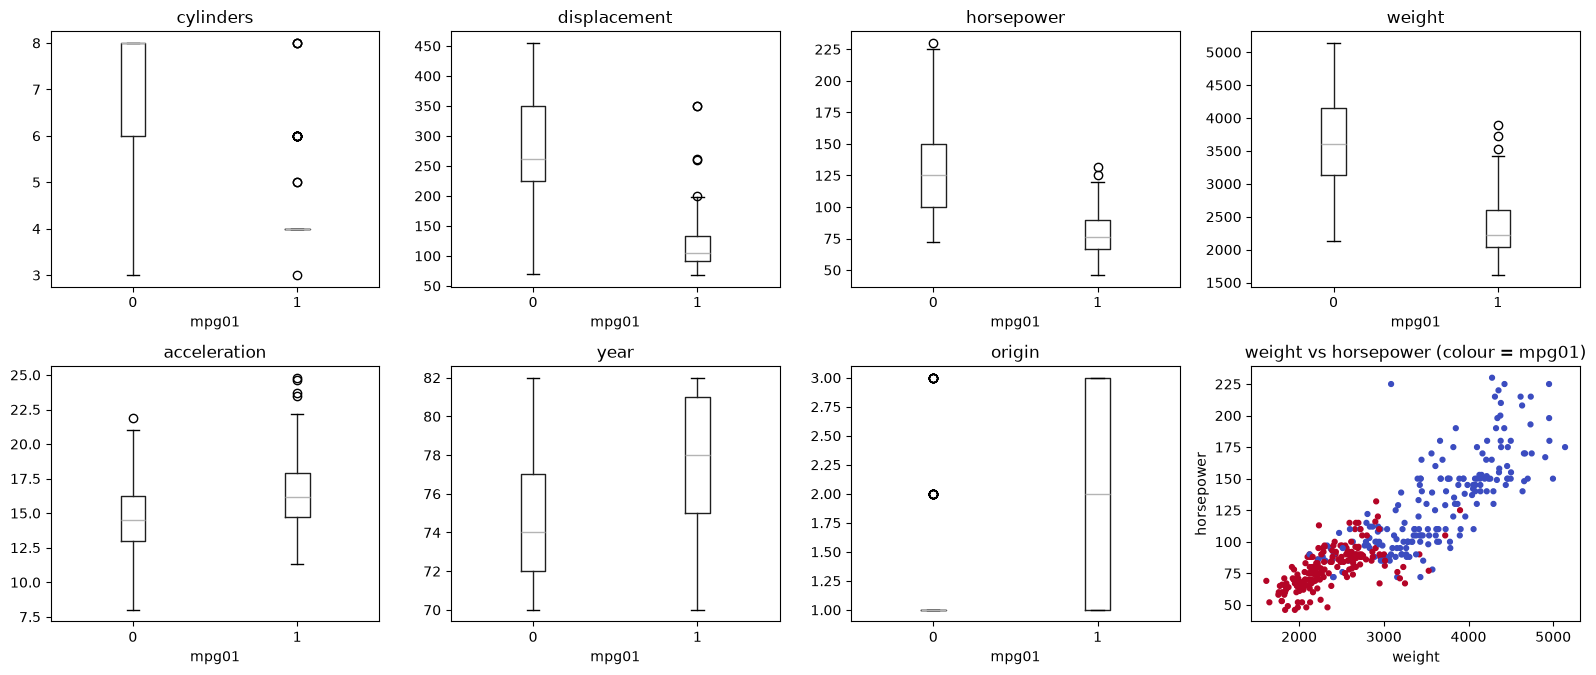

In [13]:
# Exercise 14(b)
features = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "year", "origin"]
print("Correlation of each feature with mpg01:")
print(Auto[features + ["mpg01"]].corr()["mpg01"].drop("mpg01").sort_values().round(3))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, feat in zip(axes.flat, features):
    Auto.boxplot(column=feat, by="mpg01", ax=ax, grid=False)
    ax.set(title=feat, xlabel="mpg01")
axes.flat[-1].scatter(Auto["weight"], Auto["horsepower"], c=Auto["mpg01"], cmap="coolwarm", s=12)
axes.flat[-1].set(title="weight vs horsepower (colour = mpg01)", xlabel="weight", ylabel="horsepower")
fig.suptitle("")
plt.tight_layout()
plt.show()

### Exercise 14(c)

Split the data into a training set and a test set.

In [14]:
# Exercise 14(c)
best_feats = ["cylinders", "displacement", "horsepower", "weight"]
A_train, A_test = train_test_split(Auto, test_size=0.3, random_state=0, stratify=Auto["mpg01"])
Xa_train, Xa_test = A_train[best_feats], A_test[best_feats]
ya_train, ya_test = A_train["mpg01"], A_test["mpg01"]
print(f"Training rows: {len(A_train)}, test rows: {len(A_test)}")
auto_errors = {}

Training rows: 274, test rows: 118


### Exercise 14(d)

Perform LDA on the training data in order to predict mpg01
using the variables that seemed most associated with mpg01 in (b). What is the test error of the model obtained?

In [15]:
# Exercise 14(d)
lda_auto = LDA().fit(Xa_train, ya_train)
pred = lda_auto.predict(Xa_test)
display(confusion_table(pred, ya_test))

Truth,0,1
Predicted,,
0,45,4
1,14,55


### Exercise 14(d) — test error

In [16]:
# Exercise 14(d), test error
auto_errors["LDA"] = np.mean(pred != ya_test)
print(f"LDA test error: {auto_errors['LDA']:.4f}")

LDA test error: 0.1525


### Exercise 14(e)

Perform QDA on the training data in order to predict mpg01
using the variables that seemed most associated with mpg01 in (b). What is the test error of the model obtained?

In [17]:
# Exercise 14(e)
qda_auto = QDA().fit(Xa_train, ya_train)
pred = qda_auto.predict(Xa_test)
display(confusion_table(pred, ya_test))

Truth,0,1
Predicted,,
0,46,5
1,13,54


### Exercise 14(e) — test error

In [18]:
# Exercise 14(e), test error
auto_errors["QDA"] = np.mean(pred != ya_test)
print(f"QDA test error: {auto_errors['QDA']:.4f}")

QDA test error: 0.1525


### Exercise 14(f)

Perform logistic regression on the training data in order to predict mpg01 using the variables that seemed most associated with
mpg01 in (b). What is the test error of the model obtained?

In [19]:
# Exercise 14(f)
glm_auto = sm.GLM(ya_train, sm.add_constant(Xa_train), family=sm.families.Binomial()).fit()
print(summarize(glm_auto))
pred = (glm_auto.predict(sm.add_constant(Xa_test)) > 0.5).astype(int)
display(confusion_table(pred, ya_test))
auto_errors["Logistic"] = np.mean(pred != ya_test)
print(f"Logistic regression test error: {auto_errors['Logistic']:.4f}")

                 coef  std err      z  P>|z|
const         14.6585    2.374  6.174  0.000
cylinders     -0.3265    0.420 -0.777  0.437
displacement  -0.0018    0.010 -0.182  0.856
horsepower    -0.0484    0.018 -2.640  0.008
weight        -0.0028    0.001 -3.275  0.001


Truth,0,1
Predicted,,
0,50,4
1,9,55


Logistic regression test error: 0.1102


### Exercise 14(g)

Perform naive Bayes on the training data in order to predict
mpg01 using the variables that seemed most associated with mpg01
in (b). What is the test error of the model obtained?

In [20]:
# Exercise 14(g)
nb_auto = GaussianNB().fit(Xa_train, ya_train)
pred = nb_auto.predict(Xa_test)
display(confusion_table(pred, ya_test))
auto_errors["Naive Bayes"] = np.mean(pred != ya_test)
print(f"Naive Bayes test error: {auto_errors['Naive Bayes']:.4f}")

Truth,0,1
Predicted,,
0,47,4
1,12,55


Naive Bayes test error: 0.1356


### Exercise 14(h)

Perform KNN on the training data, with several values of K, in
order to predict mpg01. Use only the variables that seemed most
associated with mpg01 in (b). What test errors do you obtain?
Which value of K seems to perform the best on this data set?

1      0.1017
3      0.0847
5      0.0847
7      0.0932
10     0.1186
15     0.1356
20     0.1356
30     0.1356
50     0.1356
75     0.1356
100    0.1356
Best K = 3 (test error 0.0847)


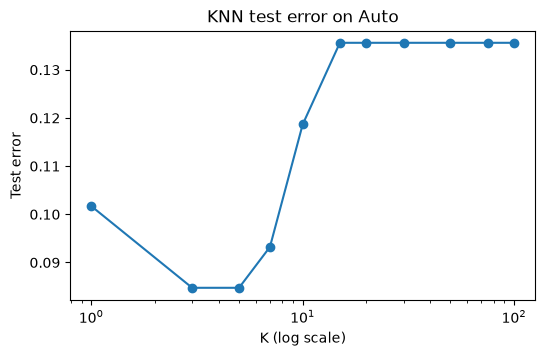

,test error
LDA,0.1525
QDA,0.1525
Logistic,0.1102
Naive Bayes,0.1356
KNN (K=3),0.0847


In [21]:
# Exercise 14(h)
scaler_auto = StandardScaler().fit(Xa_train)
Xs_train, Xs_test = scaler_auto.transform(Xa_train), scaler_auto.transform(Xa_test)
knn_errors = {}
for k in [1, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100]:
    pred = KNeighborsClassifier(n_neighbors=k).fit(Xs_train, ya_train).predict(Xs_test)
    knn_errors[k] = np.mean(pred != ya_test)
knn_errors = pd.Series(knn_errors, name="test error")
print(knn_errors.round(4).to_string())
best_k = knn_errors.idxmin()
print(f"Best K = {best_k} (test error {knn_errors[best_k]:.4f})")
auto_errors[f"KNN (K={best_k})"] = knn_errors[best_k]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(knn_errors.index, knn_errors.values, marker="o")
ax.set(xscale="log", xlabel="K (log scale)", ylabel="Test error", title="KNN test error on Auto")
plt.show()
display(pd.Series(auto_errors, name="test error").round(4).to_frame())

**Observations / conclusions**

- `mpg01` splits the 392 cars exactly in half (median mpg = 22.75).
- `cylinders`, `weight`, `displacement` and `horsepower` show the clearest separation in the boxplots (|corr| ≈ 0.67–0.76), so they are the predictors used. `year` and `origin` help less.
- Test error on a stratified 30% hold-out (118 cars): LDA 15.3%, QDA 15.3%, logistic regression 11.0%, naive Bayes 13.6%.
- KNN on standardized predictors: K = 3 and K = 5 give the lowest test error (8.5%), and error rises toward 13.6% for K ≥ 15. K ≈ 3–5 works best here. With only 118 test cars, a difference of 1–2 percentage points is just one or two cars.

---

## Exercise 15 · Applied

**Textbook: printed page 198**

This problem involves writing functions.

### Exercise 15(a)

Write a function, Power(), that prints out the result of raising 2
to the 3rd power. In other words, your function should compute
23 and print out the results.

**Hint:** Recall that x**a raises x to the power a. Use the print()
function to display the result.

In [22]:
# Exercise 15(a)
def Power():
    print(2 ** 3)

Power()

8


### Exercise 15(b)

Create a new function, Power2(), that allows you to pass any
two numbers, x and a, and prints out the value of x**a. You can
do this by beginning your function with the line
def Power2(x, a):
You should be able to call your function by entering, for instance,
Power2(3, 8)
on the command line. This should output the value of 38, namely,
6, 561.

In [23]:
# Exercise 15(b)
def Power2(x, a):
    print(x ** a)

Power2(3, 8)

6561


### Exercise 15(c)

Using the Power2() function that you just wrote, compute 103,
817, and 1313.

In [24]:
# Exercise 15(c)
Power2(10, 3)
Power2(8, 17)
Power2(131, 3)

1000
2251799813685248
2248091


### Exercise 15(d)

Now create a new function, Power3(), that actually returns the
result x**a as a Python object, rather than simply printing it
to the screen. That is, if you store the value x**a in an object
called result within your function, then you can simply return return
this result, using the following line:
return result
Note that the line above should be the last line in your function,
and it should be indented 4 spaces.

In [25]:
# Exercise 15(d)
def Power3(x, a):
    result = x ** a
    return result

print(Power3(3, 8))

6561


### Exercise 15(e)

Now using the Power3() function, create a plot of f(x) = x2.
The x-axis should display a range of integers from 1 to 10, and
the y-axis should display x2. Label the axes appropriately, and
use an appropriate title for the figure. Consider displaying either
the x-axis, the y-axis, or both on the log-scale. You can do this
by using the ax.set_xscale() and ax.set_yscale() methods of .set_xscale()
.set_yscale()
the axes you are plotting to.

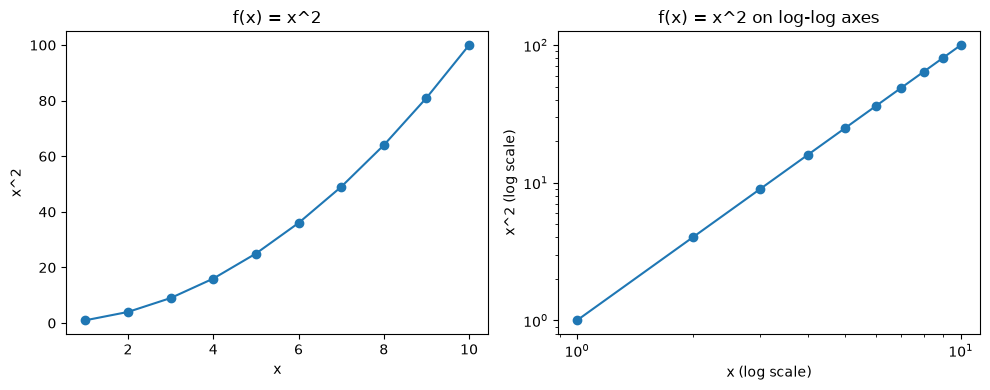

In [26]:
# Exercise 15(e)
x = np.arange(1, 11)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(x, Power3(x, 2), marker="o")
axes[0].set(title="f(x) = x^2", xlabel="x", ylabel="x^2")
axes[1].plot(x, Power3(x, 2), marker="o")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set(title="f(x) = x^2 on log-log axes", xlabel="x (log scale)", ylabel="x^2 (log scale)")
plt.tight_layout()
plt.show()

### Exercise 15(f)

Create a function, PlotPower(), that allows you to create a plot
of x against x**a for a fixed a and a sequence of values of x. For
instance, if you call
PlotPower(np.arange(1, 11), 3)
then a plot should be created with an x-axis taking on values
1, 2, . . . , 10, and a y-axis taking on values 13, 23, . . . , 103.

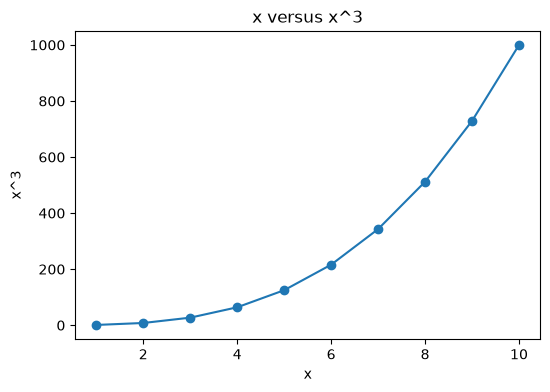

In [27]:
# Exercise 15(f)
def PlotPower(x, a):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(x, Power3(x, a), marker="o")
    ax.set(title=f"x versus x^{a}", xlabel="x", ylabel=f"x^{a}")
    plt.show()

PlotPower(np.arange(1, 11), 3)

**Observations / conclusions**

`Power()` prints $2^3 = 8$ and `Power2(3, 8)` prints 6561. $10^3 = 1000$, $8^{17} = 2{,}251{,}799{,}813{,}685{,}248$, $131^3 = 2{,}248{,}091$. `Power3` *returns* its value, so it can be reused in plots. On log-log axes, $x^2$ becomes a straight line with slope 2.

---

## Exercise 16 · Applied

**Textbook: printed page 199**

Using the Boston data set, fit classification models in order to predict
whether a given suburb has a crime rate above or below the median.
Explore logistic regression, LDA, naive Bayes, and KNN models using
various subsets of the predictors. Describe your findings.

**Hint:** You will have to create the response variable yourself, using the
variables that are contained in the Boston data set.

In [28]:
# Exercise 16
Boston = load_data("Boston")
Boston["crim01"] = (Boston["crim"] > Boston["crim"].median()).astype(int)
print("Correlation with crim01:")
print(Boston.drop(columns=["crim"]).corr()["crim01"].drop("crim01").sort_values().round(3))

B_train, B_test = train_test_split(Boston, test_size=0.3, random_state=0, stratify=Boston["crim01"])
subsets = {
    "nox, rad, dis, age": ["nox", "rad", "dis", "age"],
    "nox, rad, tax, indus, age, dis": ["nox", "rad", "tax", "indus", "age", "dis"],
    "all 12 predictors": [c for c in Boston.columns if c not in ("crim", "crim01")],
}
rows = []
for name, cols in subsets.items():
    sc = StandardScaler().fit(B_train[cols])
    Xtr, Xte = sc.transform(B_train[cols]), sc.transform(B_test[cols])
    ytr, yte = B_train["crim01"].values, B_test["crim01"].values
    glm = sm.GLM(ytr, sm.add_constant(Xtr), family=sm.families.Binomial()).fit()
    preds = {
        "Logistic": (glm.predict(sm.add_constant(Xte)) > 0.5).astype(int),
        "LDA": LDA().fit(Xtr, ytr).predict(Xte),
        "Naive Bayes": GaussianNB().fit(Xtr, ytr).predict(Xte),
    }
    for k in [1, 3, 5, 10, 20]:
        preds[f"KNN K={k}"] = KNeighborsClassifier(n_neighbors=k).fit(Xtr, ytr).predict(Xte)
    for m, p in preds.items():
        rows.append({"predictors": name, "method": m, "test error": np.mean(p != yte)})
results_16 = pd.DataFrame(rows).pivot(index="method", columns="predictors", values="test error")
display(results_16.round(3))

Correlation with crim01:
dis       -0.616
zn        -0.436
medv      -0.263
rm        -0.156
chas       0.070
ptratio    0.254
lstat      0.453
indus      0.603
tax        0.609
age        0.614
rad        0.620
nox        0.723
Name: crim01, dtype: float64


predictors,all 12 predictors,"nox, rad, dis, age","nox, rad, tax, indus, age, dis"
method,,,
KNN K=1,0.086,0.125,0.086
KNN K=10,0.211,0.125,0.099
KNN K=20,0.224,0.145,0.112
KNN K=3,0.092,0.118,0.066
KNN K=5,0.125,0.125,0.086
LDA,0.171,0.171,0.178
Logistic,0.132,0.164,0.138
Naive Bayes,0.230,0.184,0.191


**Observations / conclusions**

The response `crim01` is 1 when a tract's crime rate is above the median. The predictors most associated with it are `nox` (0.72), `rad`, `age`, `tax`, `indus` (≈ 0.60–0.62) and `dis` (−0.62).
On a 30% stratified hold-out, KNN does clearly best: K = 3 with `nox, rad, tax, indus, age, dis` reaches 6.6% test error, and K = 1 reaches about 8.6% with that subset or with all predictors. Logistic regression is next (≈ 13–16%), then LDA (≈ 17–18%) and naive Bayes (≈ 18–23%).
KNN's advantage suggests the boundary between high- and low-crime tracts is strongly nonlinear: high-crime tracts cluster tightly in a few places (e.g. `rad` = 24, high `nox`, short `dis`). Adding weak predictors hurts KNN at larger K and hurts naive Bayes.